In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


In [ ]:
# load the dataset
mpg = sns.load_dataset("mpg")

In [ ]:
# understand the dataset
mpg.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   mpg           398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   displacement  398 non-null    float64
 3   horsepower    392 non-null    float64
 4   weight        398 non-null    int64  
 5   acceleration  398 non-null    float64
 6   model_year    398 non-null    int64  
 7   origin        398 non-null    object 
 8   name          398 non-null    object 
dtypes: float64(4), int64(3), object(2)
memory usage: 28.1+ KB


In [ ]:
mpg.describe()


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
count,398.000000,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000
mean,23.514573,5.454774,193.425879,104.469388,2970.424623,15.568090,76.010050
std,7.815984,1.701004,104.269838,38.491160,846.841774,2.757689,3.697627
min,9.000000,3.000000,68.000000,46.000000,1613.000000,8.000000,70.000000
25%,17.500000,4.000000,104.250000,75.000000,2223.750000,13.825000,73.000000
50%,23.000000,4.000000,148.500000,93.500000,2803.500000,15.500000,76.000000
75%,29.000000,8.000000,262.000000,126.000000,3608.000000,17.175000,79.000000
max,46.600000,8.000000,455.000000,230.000000,5140.000000,24.800000,82.000000


In [ ]:
# data cleaning
mpg.isnull().sum()

,0
mpg,0
cylinders,0
displacement,0
horsepower,6
weight,0
acceleration,0
model_year,0
origin,0
name,0


In [ ]:
# remove duplicates
mpg = mpg.drop_duplicates()

In [ ]:
# reset index
mpg = mpg.reset_index(drop = True)
mpg.shape

(398, 9)

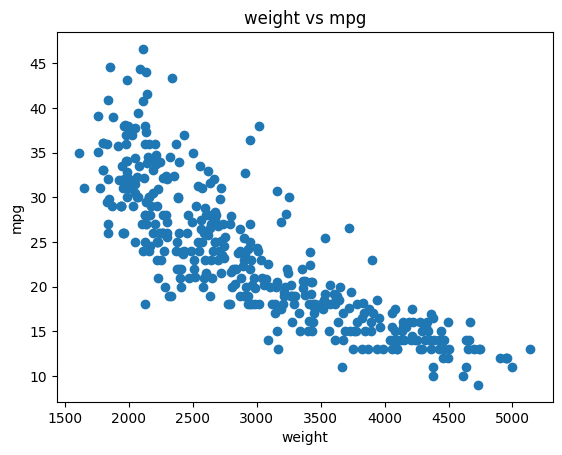

In [ ]:
#EDA
plt.figure()
plt.scatter(mpg["weight"],mpg["mpg"])
plt.xlabel("weight")
plt.ylabel("mpg")
plt.title("weight vs mpg")
plt.show()

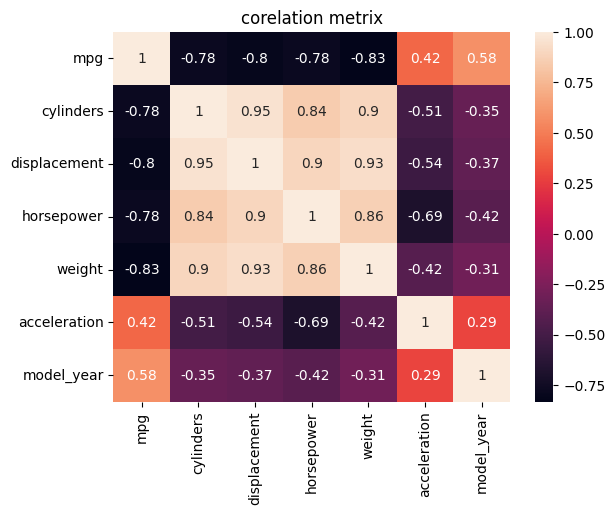

In [ ]:
plt.figure()
sns.heatmap(mpg.corr(numeric_only=True), annot=True)
plt.title("corelation metrix")
plt.show()

In [ ]:
# feature selection
X = mpg[["weight"]]
y = mpg["mpg"]


In [ ]:
# Train dataset
X_train, X_test, Y_train, Y_test = train_test_split(X,y,test_size=0.2, random_state=42)

In [ ]:
# ploynomial features  -- convert all the featrue into polynomial features
ploy = PolynomialFeatures(degree=2)
X_train_ploy = ploy.fit_transform(X_train)
X_test_ploy = ploy.fit_transform(X_test)

In [ ]:
# train model
model = LinearRegression()
model.fit(X_train_ploy, Y_train)


LinearRegression()

In [ ]:
# predictions
y_predict = model.predict(X_test_ploy)

In [ ]:
#evaluation
print("mse", mean_squared_error(Y_test, y_predict))
print("r2", r2_score(Y_test, y_predict))


mse 13.150522130757171
r2 0.7554139494160395


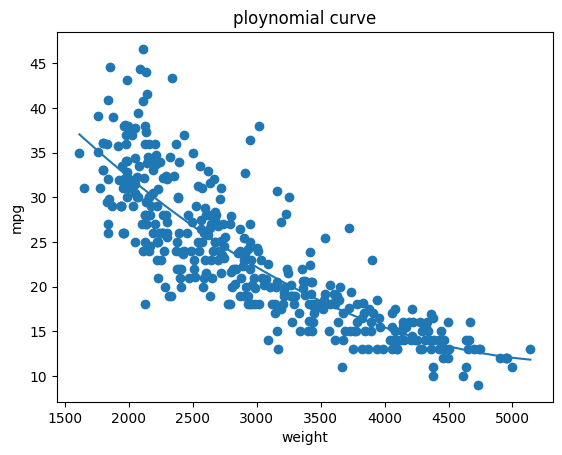

In [ ]:
# polynomial curve visualization
sorted_zip = sorted(zip(X["weight"], model.predict(ploy.transform(X))))
X_sorted, y_sorted = zip(*sorted_zip)

plt.figure()
plt.scatter(X,y)
plt.plot(X_sorted, y_sorted)
plt.xlabel("weight")
plt.ylabel("mpg")
plt.title("ploynomial curve")
plt.show()